# H1: Is Kryptonite-$n$ learnable by standard models?

**Claim refuted (A).** The mock paper argues that because polynomial logistic regression never exceeds 59%,
Kryptonite-$n$ is a counterexample to universal function approximation and cannot be solved by machine learning.

**Hypothesis H1.** A standard model trained from scratch exceeds the paper's 90% target; the paper's failure is a
property of its model choice, not of the data.

* Independent variable: the model class (logistic regression with $d=1,2$; MLP on raw inputs; MLP on sign inputs).
* Dependent variable: test accuracy.
* Controls: identical splits for every model (5 seeds, stratified 60/20/20), all hyper-parameters chosen on the
  validation split only, test split used once per seed.
* Decision rule (fixed before looking at test data): the model with the best validation accuracy is checked against
  the target with Chebyshev half-width $\varepsilon = 1/(2\sqrt{N\delta})$, $\delta=0.05$. H1 is supported for a given
  $n$ if $\hat a - \varepsilon > 0.90$. We also check that it beats the best logistic regression by more than both
  intervals, $\hat a - \varepsilon > \hat a_{\text{LR}} + \varepsilon$, with a union bound over the $m=4$ models
  compared ($\varepsilon = 1/(2\sqrt{N\delta/m})$).

In [1]:
import joblib
import numpy as np
import matplotlib.pyplot as plt
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import PolynomialFeatures

from include.config import NS, SEEDS, TARGET, RESULTS
from include.data import load, to_sign, split
from include.models import mlp, fit, predict_logits
from include.stats import chebyshev_eps, mean_std
from include.tracking import track, save_json
from include.figures import use_paper_style, savefig
from include.plots_h1 import plot_h1_models, plot_h1_seeds

use_paper_style()
torch.set_num_threads(4)
MODELS = ["LogReg (d=1)", "LogReg (d=2)", "MLP (raw x)", "MLP (sign x)"]
TAGS = dict(zip(MODELS, ["logreg_d1", "logreg_d2", "mlp_raw", "mlp_sign"]))  # short names for saved files
SAVED = RESULTS / "H1"  # every trained model, split and set of test predictions goes here
SAVED.mkdir(parents=True, exist_ok=True)

## 1. Model fitting functions

Logistic regression minimises the regularised Bernoulli NLL, which is convex, so L-BFGS (a quasi-Newton form of
gradient descent) run to convergence reaches the global minimum. scikit-learn's `C` is $1/\lambda$.
The MLP is trained with AdamW and early stopping on validation accuracy (`fit` in `include/models.py`). Its starting
weights are set by its seed, so any single fit can be rerun on its own and gives the same model.

In [2]:
def fit_logreg(X_tr, y_tr, X_va, y_va, degree, C):
    poly = PolynomialFeatures(degree, include_bias=False)
    clf = LogisticRegression(C=C, max_iter=5000).fit(poly.fit_transform(X_tr), y_tr)
    return (poly, clf), clf.score(poly.transform(X_va), y_va)


def logreg_predict(lr_model, X):
    poly, clf = lr_model
    return clf.predict(poly.transform(X))


def fit_mlp(X_tr, y_tr, X_va, y_va, width, depth, weight_decay, seed):
    torch.manual_seed(seed)  # starting weights depend only on the seed
    model = mlp(X_tr.shape[1], width, depth)
    return fit(model, X_tr, y_tr, X_va, y_va, weight_decay=weight_decay, seed=seed)


def mlp_predict(model, X):
    return (predict_logits(model, X) > 0).astype(int)

## 2. Hyper-parameter selection (seed-0 validation split only)

For each $n$ we pick logistic regression's $\lambda$ from a grid and the MLP's width, depth and weight decay from a
small grid, using **only** the seed-0 validation accuracy. The test split is not touched here.

In [3]:
C_GRID = [0.01, 0.1, 1.0, 10.0]
MLP_GRID = [dict(width=128, depth=2, weight_decay=1e-2),
            dict(width=256, depth=3, weight_decay=1e-2),
            dict(width=512, depth=2, weight_decay=1e-1)]

chosen = {}
with track("H1_hparam_selection"):
    for n in NS:
        X, y = load(n)
        X_tr, y_tr, X_va, y_va, _, _ = split(X, y, seed=0)
        chosen[n] = {}
        for d in (1, 2):
            scores = {C: fit_logreg(X_tr, y_tr, X_va, y_va, d, C)[1] for C in C_GRID}
            chosen[n][f"LogReg (d={d})"] = {"C": max(scores, key=scores.get)}
            print(f"n={n} LogReg d={d}: val acc by C {scores}")
        S_tr, S_va = to_sign(X_tr), to_sign(X_va)
        scores = []
        for cfg in MLP_GRID:
            _, va = fit_mlp(S_tr, y_tr, S_va, y_va, **cfg, seed=0)
            scores.append(va)
            print(f"n={n} MLP {cfg}: val acc {va:.3f}")
        best = MLP_GRID[int(np.argmax(scores))]
        chosen[n]["MLP (raw x)"] = chosen[n]["MLP (sign x)"] = best
print(chosen)
save_json({str(k): v for k, v in chosen.items()}, "H1_hparams.json")  # H2 and the final predictions reuse these

n=20 LogReg d=1: val acc by C {0.01: 0.4995833333333333, 0.1: 0.49833333333333335, 1.0: 0.49875, 10.0: 0.49833333333333335}


n=20 LogReg d=2: val acc by C {0.01: 0.5533333333333333, 0.1: 0.54875, 1.0: 0.5491666666666667, 10.0: 0.5483333333333333}


n=20 MLP {'width': 128, 'depth': 2, 'weight_decay': 0.01}: val acc 0.917


n=20 MLP {'width': 256, 'depth': 3, 'weight_decay': 0.01}: val acc 0.934


n=20 MLP {'width': 512, 'depth': 2, 'weight_decay': 0.1}: val acc 0.939
n=30 LogReg d=1: val acc by C {0.01: 0.5025, 0.1: 0.502, 1.0: 0.502, 10.0: 0.502}


n=30 LogReg d=2: val acc by C {0.01: 0.53575, 0.1: 0.53925, 1.0: 0.53925, 10.0: 0.53825}


... (3 outputs left out)

n=40 LogReg d=2: val acc by C {0.01: 0.5390625, 0.1: 0.54078125, 1.0: 0.54109375, 10.0: 0.54140625}


n=40 MLP {'width': 128, 'depth': 2, 'weight_decay': 0.01}: val acc 0.939


n=40 MLP {'width': 256, 'depth': 3, 'weight_decay': 0.01}: val acc 0.945


n=40 MLP {'width': 512, 'depth': 2, 'weight_decay': 0.1}: val acc 0.946
[H1_hparam_selection] 1731s, ~21.63 Wh, ~2.68 gCO2e
{20: {'LogReg (d=1)': {'C': 0.01}, 'LogReg (d=2)': {'C': 0.01}, 'MLP (raw x)': {'width': 512, 'depth': 2, 'weight_decay': 0.1}, 'MLP (sign x)': {'width': 512, 'depth': 2, 'weight_decay': 0.1}}, 30: {'LogReg (d=1)': {'C': 0.01}, 'LogReg (d=2)': {'C': 0.1}, 'MLP (raw x)': {'width': 256, 'depth': 3, 'weight_decay': 0.01}, 'MLP (sign x)': {'width': 256, 'depth': 3, 'weight_decay': 0.01}}, 40: {'LogReg (d=1)': {'C': 0.1}, 'LogReg (d=2)': {'C': 10.0}, 'MLP (raw x)': {'width': 512, 'depth': 2, 'weight_decay': 0.1}, 'MLP (sign x)': {'width': 512, 'depth': 2, 'weight_decay': 0.1}}}


## 3. Main experiment: 5 seeds x 3 datasets x 4 models

Each seed draws a fresh stratified split; all four models see exactly the same split. Every trained model is saved to
`results/H1/` together with the row indices of its split and its test-set predictions.

In [4]:
results = {n: {m: {"val": [], "test": []} for m in MODELS} for n in NS}
with track("H1_main"):
    for n in NS:
        X, y = load(n)
        for seed in SEEDS:
            X_tr, y_tr, X_va, y_va, X_te, y_te = split(X, y, seed)
            idx_tr, _, idx_va, _, idx_te, _ = split(np.arange(len(y)), y, seed)  # the same rows, as indices
            preds = {}
            for d in (1, 2):
                m = f"LogReg (d={d})"
                lr_model, va = fit_logreg(X_tr, y_tr, X_va, y_va, d, **chosen[n][m])
                joblib.dump(lr_model, SAVED / f"{TAGS[m]}_n{n}_seed{seed}.joblib")
                preds[m] = logreg_predict(lr_model, X_te)
                results[n][m]["val"].append(va)
            for m, f in (("MLP (raw x)", lambda A: A), ("MLP (sign x)", to_sign)):
                model, va = fit_mlp(f(X_tr), y_tr, f(X_va), y_va, **chosen[n][m], seed=seed)
                torch.save(model.state_dict(), SAVED / f"{TAGS[m]}_n{n}_seed{seed}.pt")
                preds[m] = mlp_predict(model, f(X_te))
                results[n][m]["val"].append(va)
            for m in MODELS:
                results[n][m]["test"].append(float((preds[m] == y_te).mean()))
            np.savez(SAVED / f"split_n{n}_seed{seed}.npz", train=idx_tr, val=idx_va, test=idx_te,
                     **{TAGS[m]: preds[m] for m in MODELS})
            print(f"n={n} seed={seed}: " + ", ".join(f"{m} {results[n][m]['test'][-1]:.3f}" for m in MODELS),
                  flush=True)
        results[n]["N_test"] = len(y_te)

n=20 seed=0: LogReg (d=1) 0.508, LogReg (d=2) 0.532, MLP (raw x) 0.914, MLP (sign x) 0.928


n=20 seed=1: LogReg (d=1) 0.499, LogReg (d=2) 0.549, MLP (raw x) 0.910, MLP (sign x) 0.920


n=20 seed=2: LogReg (d=1) 0.512, LogReg (d=2) 0.539, MLP (raw x) 0.916, MLP (sign x) 0.929


n=20 seed=3: LogReg (d=1) 0.501, LogReg (d=2) 0.533, MLP (raw x) 0.930, MLP (sign x) 0.937


n=20 seed=4: LogReg (d=1) 0.513, LogReg (d=2) 0.552, MLP (raw x) 0.907, MLP (sign x) 0.933


n=30 seed=0: LogReg (d=1) 0.501, LogReg (d=2) 0.517, MLP (raw x) 0.905, MLP (sign x) 0.936


... (6 outputs left out)

n=40 seed=2: LogReg (d=1) 0.497, LogReg (d=2) 0.522, MLP (raw x) 0.945, MLP (sign x) 0.951


n=40 seed=3: LogReg (d=1) 0.500, LogReg (d=2) 0.525, MLP (raw x) 0.944, MLP (sign x) 0.950


n=40 seed=4: LogReg (d=1) 0.497, LogReg (d=2) 0.531, MLP (raw x) 0.944, MLP (sign x) 0.950


[H1_main] 23469s, ~293.36 Wh, ~36.38 gCO2e


## 4. Decision rule

The model is picked on mean validation accuracy, so the 90% check is about one model and uses $\varepsilon$ with $m=1$.
The comparison with the best logistic regression uses a union bound over the $m=4$ models. $\varepsilon$ uses the size
of one test split, so each interval holds with probability at least $1-\delta = 0.95$ (per seed).

In [5]:
summary = {}
print(f"{'n':>3} {'model':<14} {'val acc':>8} {'test acc (mean +- sd)':>22}")
for n in NS:
    eps_target = chebyshev_eps(results[n]["N_test"])                   # one model, chosen on validation
    eps_compare = chebyshev_eps(results[n]["N_test"], m=len(MODELS))  # union bound over the 4 models
    summary[n] = {"eps": eps_compare, "eps_target": eps_target}
    for m in MODELS:
        val = float(np.mean(results[n][m]["val"]))
        mu, sd = mean_std(results[n][m]["test"])
        summary[n][m] = {"val": val, "mean": mu, "sd": sd}
        print(f"{n:>3} {m:<14} {val:>8.3f} {mu:>14.3f} +- {sd:.3f}")

    chosen_model = max(MODELS, key=lambda m: summary[n][m]["val"])
    a = summary[n][chosen_model]["mean"]
    best_lr = max(summary[n][m]["mean"] for m in MODELS[:2])
    summary[n]["chosen_model"] = chosen_model
    summary[n]["reaches_target"] = bool(a - eps_target > TARGET)
    summary[n]["beats_LR"] = bool(a - eps_compare > best_lr + eps_compare)
    print(f"    chosen on validation: {chosen_model}")
    print(f"    {a:.3f} - {eps_target:.3f} > 0.90 (H1 supported): {summary[n]['reaches_target']}")
    print(f"    beats best LR by more than both intervals (eps {eps_compare:.3f}): {summary[n]['beats_LR']}\n")

save_json({"chosen": {str(k): v for k, v in chosen.items()},
           "results": {str(k): v for k, v in results.items()},
           "summary": {str(k): v for k, v in summary.items()}}, "H1_learnability.json")

  n model           val acc  test acc (mean +- sd)
 20 LogReg (d=1)      0.502          0.507 +- 0.006
 20 LogReg (d=2)      0.548          0.541 +- 0.009
 20 MLP (raw x)       0.920          0.916 +- 0.009
 20 MLP (sign x)      0.933          0.929 +- 0.007
    chosen on validation: MLP (sign x)
    0.929 - 0.046 > 0.90 (H1 supported): False
    beats best LR by more than both intervals (eps 0.091): True

 30 LogReg (d=1)      0.500          0.497 +- 0.008
 30 LogReg (d=2)      0.534          0.530 +- 0.011
 30 MLP (raw x)       0.912          0.911 +- 0.010
 30 MLP (sign x)      0.931          0.928 +- 0.009
    chosen on validation: MLP (sign x)
    0.928 - 0.035 > 0.90 (H1 supported): False
    beats best LR by more than both intervals (eps 0.071): True

 40 LogReg (d=1)      0.501          0.498 +- 0.006
 40 LogReg (d=2)      0.533          0.530 +- 0.007
 40 MLP (raw x)       0.946          0.944 +- 0.001
 40 MLP (sign x)      0.949          0.949 +- 0.002
    chosen on validatio

## 5. Check the saved files

Reload every saved model and split, predict the test rows again, and check that this gives exactly the saved
predictions and the test accuracies above. No training happens here.

In [6]:
for n in NS:
    X, y = load(n)
    for i, seed in enumerate(SEEDS):
        saved = np.load(SAVED / f"split_n{n}_seed{seed}.npz")
        X_te, y_te = X[saved["test"]], y[saved["test"]]
        for m in MODELS:
            if m.startswith("LogReg"):
                pred = logreg_predict(joblib.load(SAVED / f"{TAGS[m]}_n{n}_seed{seed}.joblib"), X_te)
            else:
                model = mlp(n, chosen[n][m]["width"], chosen[n][m]["depth"])
                model.load_state_dict(torch.load(SAVED / f"{TAGS[m]}_n{n}_seed{seed}.pt", weights_only=True))
                pred = mlp_predict(model, to_sign(X_te) if m == "MLP (sign x)" else X_te)
            assert np.array_equal(pred, saved[TAGS[m]]), (n, seed, m)
            assert float((pred == y_te).mean()) == results[n][m]["test"][i], (n, seed, m)
print("every saved model reproduces its saved test predictions and accuracy")

every saved model reproduces its saved test predictions and accuracy


## 6. Figures

Points are seed means; error bars are $\pm\varepsilon$ (Chebyshev, union bound over the 4 models). The dashed line is
the paper's 90% target. (`report_figures.ipynb` redraws these from `results/H1_learnability.json` without retraining.)

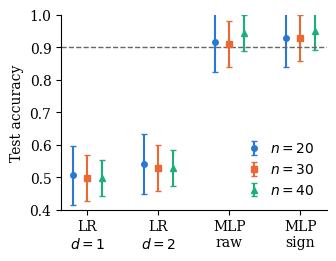

In [7]:
fig = plot_h1_models(summary, MODELS)
savefig(fig, "H1_models")
plt.show()

Every seed's test accuracy, to show how much the seeds vary.

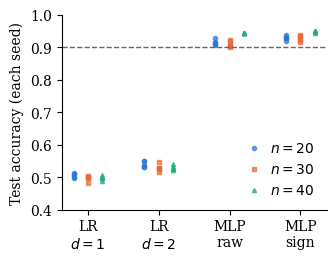

In [8]:
fig = plot_h1_seeds(results, MODELS)
savefig(fig, "H1_seeds")
plt.show()